# Step 1: Data preprocessing and feature engineering

**Pipeline.** `step1_data_preprocess.ipynb` (this notebook) → `step2_baselines.ipynb` → `step3_lightgbm.ipynb` (base model) → `step3_lambdarank.ipynb` (final model) and `step3_attention.ipynb` (extension)
This notebook turns the raw JDSearch files into one feature table (one row per user × candidate product), plus the inputs that team 3's model needs, and saves them with a few small analysis tables. Step 2 runs the baselines (including team 3's hybrid NCF, our prior baseline) and step 3 trains our LightGBM ranker and compares everything.

**What it covers.**
- Parsing the raw behaviour file, the user-level train/val/test split and negative sampling.
- Prof's interim feedback: history intervals converted to elapsed days before the final search, and how clicks, carts and orders shift as we trace history back in time (Section 3).
- Time-aware history features built from that finding (Section 6).
- The history matrix for the collaborative-filtering (MF) baseline (Section 7).
- The inputs for team 3's hybrid NCF, rebuilt the way their code builds them (Section 8).


## How to run in Colab
1. Runtime → Change runtime type → CPU, **High-RAM** (needed for the full data; standard Colab's 12.7 GB is not enough).
2. Runtime → Run all. The first cell asks you to sign in to Google so it can download the data from the group's Drive folder by file ID
3. For a quick test, set `MAX_USERS = 30000` in the config cell. For the results we report, set it to `0` (all users).
4. Outputs go to /content/artifacts. The group's copy is the shared BT4222_artifacts folder (id in the config cell). The last two cells upload to it only if UPLOAD_ARTIFACTS = True (default False), so a normal re-run never overwrites the shared files.
5. **Before saving the notebook, keep the outputs** (do not clear them, and make sure Edit → Notebook settings → "Omit code cell output when saving" is off)

| # | Decision | Choice |
|---|---|---|
| D1 | Rows we drop | Slates with no engaged candidate (2,103) |
| D2 | Candidate order | Shuffled within each slate with a fixed seed; list position is never a feature |
| D3 | Train/val/test split | By user, 80/10/10, stratified by history-length quartile, seed 42 |
| D4 | Target | Binary: label ≥ 1. Grades 1–3 used only to score NDCG@10 |
| D5 | Time unit | Gaps are seconds; every history action gets *elapsed days before the final search* |
| D6 | Time windows | 0–7 days, 7–90 days, 90–365 days, matching how long JD keeps each action type |
| D7 | Feature families | User × candidate affinity (item, shop, brand, category) per window, with recency; popularity from train users only; query–name overlap as context |
| D8 | Negative sampling | Train only: all positives plus 20 random negatives per slate. Val and test use full slates |
| D11 | Possible leakage | Drop history actions exactly 1 second before the search, while parsing (`LEAK_GUARD_SECONDS = 1`). Later bands look like normal recency |
| D12 | Training performance | 10,000 train users keep their full slate, used only to report training metrics |
| D13 | CF baseline | Implicit matrix factorisation (truncated SVD) on the user × product history matrix |
| D14 | History cap | None: user × product features use each user's full history (HISTORY_CAP = None), changed from the interim report's last-100 cap |
| D15 | Team 3 inputs | Their 15 user "meta" features, history sequences and 1:4 sampled lists, rebuilt from their code |

D9 and D10 (model and evaluation) are in steps 2 and 3.

## 1. Setup

In [ ]:
import os, sys, time, gc, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules

# ---- config: change these, nothing else ----
DATA_DIR = os.environ.get("JD_DATA_DIR", "/content/jd")              # where the fetch cell puts the raw data
ART_DIR = os.environ.get("JD_ART_DIR", "/content/artifacts")         # feature table and analysis tables are saved here
DRIVE_ARTIFACT_FOLDER = "BT4222_artifacts"                  # shared folder the group reads (steps 2 and 3)
ARTIFACT_FOLDER_ID = "1Yb4AGglIJV4Pdd8Sx6NozG8Klh6uweqH"   # its Drive id, same for everyone
UPLOAD_ARTIFACTS = False                                    # True only to replace the shared files (needs edit access)
MAX_USERS = int(os.environ.get("JD_MAX_USERS", 0))                   # 0 = all users; 30000 for a quick run
SEED = 42
NEG_PER_SLATE = 20             # D8
TRAIN_EVAL_USERS = 10000       # D12
WIN_EDGES = [7, 90]            # D6: windows are [0, 7), [7, 90), [90, 365] days before the search
LEAK_GUARD_SECONDS = 1         # D11: drop history actions this close to the search (1 = 1 second before the test search)
MF_DIM = 32                    # D13: latent factors for the MF baseline
MF_MIN_COUNT = 2               # D13: products need this many history actions to get a factor (candidates need 1)
HISTORY_CAP = None             # D14: last N actions per user for user x product features (None = full history)
T3_NEG_RATIO = 4               # D15: team 3 kept 4 negatives per positive in every split
T3_MAX_LEN = 200               # D15: team 3's LSTM reads the last 200 actions
T3_ITEM_VOCAB = 1_000_000      # D15: most frequent history products that get their own ID embedding
# --------------------------------------------

BEHAVIOR_PATH = f"{DATA_DIR}/user_behavior_data.txt"
CHUNKS_DIR = f"{DATA_DIR}/product_chunks"
OUT_DIR = f"{ART_DIR}/figures"
os.makedirs(OUT_DIR, exist_ok=True)
WIN_NAMES = ["0-7d", "7-90d", "90-365d"]
print("pandas", pd.__version__, "| numpy", np.__version__, "| Colab:", IN_COLAB)

pandas 2.2.3 | numpy 2.4.6 | Colab: True


### Get the data


In [ ]:
if IN_COLAB and not os.path.exists(f"{DATA_DIR}/download_complete"):
    from google.colab import auth
    auth.authenticate_user()
    import io
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload

    svc = build("drive", "v3")
    os.makedirs(CHUNKS_DIR, exist_ok=True)
    BEHAVIOR_ID = "1V0gUY3ALNDYaN83ERZQxd5LIllnMbqnK"      # JDSearch_raw/user_behavior_data.txt
    CHUNKS_FOLDER_ID = "1xwOCielQqOHzCT0cT3qsl8xm5m3-QM4r"  # JDSearch_raw/product_chunks
    RETRIES = 8                                             # waits and retries when Drive rate-limits us

    def fetch(file_id, path, size):
        if os.path.exists(path) and os.path.getsize(path) == size:     # a partial file does not count
            return
        tmp = path + ".part"
        req = svc.files().get_media(fileId=file_id, supportsAllDrives=True)
        with io.FileIO(tmp, "wb") as fh:
            dl = MediaIoBaseDownload(fh, req, chunksize=100 * 1024 * 1024)
            done = False
            while not done:
                _, done = dl.next_chunk(num_retries=RETRIES)
        assert os.path.getsize(tmp) == size, f"incomplete download: {path}"
        os.replace(tmp, path)                                          # only a finished file gets the real name
        print("downloaded", path)

    b = svc.files().get(fileId=BEHAVIOR_ID, fields="size", supportsAllDrives=True).execute(num_retries=RETRIES)
    fetch(BEHAVIOR_ID, BEHAVIOR_PATH, int(b["size"]))
    token = None
    n_listed = 0
    while True:
        r = svc.files().list(q=f"'{CHUNKS_FOLDER_ID}' in parents and trashed=false", pageSize=1000,
                             fields="nextPageToken, files(id, name, size)", pageToken=token,
                             supportsAllDrives=True, includeItemsFromAllDrives=True).execute(num_retries=RETRIES)
        for f in r["files"]:
            if f["name"].endswith(".parquet"):
                n_listed += 1
                fetch(f["id"], f"{CHUNKS_DIR}/{f['name']}", int(f["size"]))
        token = r.get("nextPageToken")
        if not token:
            break
    assert n_listed and len(glob.glob(f"{CHUNKS_DIR}/*.parquet")) == n_listed, "chunk count does not match Drive"
    open(f"{DATA_DIR}/download_complete", "w").close()
print("behaviour file:", os.path.exists(BEHAVIOR_PATH), "| product chunks:", len(glob.glob(f"{CHUNKS_DIR}/*.parquet")))

downloaded /content/jd/user_behavior_data.txt
downloaded /content/jd/product_chunks/product_chunk_121.parquet
downloaded /content/jd/product_chunks/product_chunk_120.parquet
downloaded /content/jd/product_chunks/product_chunk_119.parquet
downloaded /content/jd/product_chunks/product_chunk_118.parquet
downloaded /content/jd/product_chunks/product_chunk_117.parquet
downloaded /content/jd/product_chunks/product_chunk_116.parquet
downloaded /content/jd/product_chunks/product_chunk_115.parquet
downloaded /content/jd/product_chunks/product_chunk_114.parquet
downloaded /content/jd/product_chunks/product_chunk_113.parquet
downloaded /content/jd/product_chunks/product_chunk_112.parquet
downloaded /content/jd/product_chunks/product_chunk_111.parquet
downloaded /content/jd/product_chunks/product_chunk_110.parquet
downloaded /content/jd/product_chunks/product_chunk_109.parquet
downloaded /content/jd/product_chunks/product_chunk_108.parquet
downloaded /content/jd/product_chunks/product_chunk_107.pa

## 2. Parse the behaviour file into three tables

Loading the whole file with `pd.read_csv` and then `.apply(split)` keeps every list twice, as text and as Python lists, and does not fit next to the features. So we read it line by line into three compact tables:

- `U`: one row per user (query and user-level facts)
- `C`: one row per candidate shown in the final search (`user`, `wid`, `label`)
- `H`: one row per history action (`user`, `wid`, action type, whether it had a query, **days before the final search**)

> **Decision D1: drop slates with no engaged candidate.** 2,103 of 173,831 users engaged with nothing in their last search. NDCG and MRR are undefined for them (every ordering scores the same), and as training rows they add only negatives that we cannot tell apart from "never looked". The other 171,728 users remain.

> **Decision D2: shuffle candidates within each slate (seed 42), never use list position.** The stored list is sorted by label: engaged products come first in 100% of slates (interim report). Any feature tied to position would leak the label, and evaluating in stored order would make ties look perfect. We shuffle once while parsing, so every later step (negative sampling, tie-breaking in evaluation) sees a random order.

> **Decision D5: time is in seconds; convert to elapsed days before the search.** `history_time_list` has one more value than the other lists: a leading 0, the gaps between consecutive actions, and finally the gap from the last action to the search. An action's time before the search is the sum of every gap after it, which is a reversed cumulative sum.

In [ ]:
SEP_Q = "\x18"            # ^X separates the term ids inside one query or product name
TYPE_CODE = {"CLICK": 0, "CART": 1, "FLW": 2, "ORD": 3}
TYPE_NAME = ["CLICK", "CART", "FLW", "ORD"]
COLS = ["query", "candidate_wid_list", "candidate_label_list", "history_qry_list",
        "history_wid_list", "history_type_list", "history_time_list"]

def split(s, sep="_"):
    return [] if s == "" else s.split(sep)

def to_int64(lst):
    return np.array(lst, dtype=np.float64).astype(np.int64)   # ids and labels can be written as "123.0"

def elapsed_days(gaps, k):
    # gaps = [0, g1, ..., g_{k-1}, gap to search]; action i happened sum(gaps[i+1:]) seconds before the search
    g = gaps[: k + 1]
    return (np.cumsum(g[::-1])[::-1][1:] / 86400).astype(np.float32)

assert np.allclose(elapsed_days(np.array([0, 12, 4, 5.]), 3) * 86400, [21, 9, 5])   # the guide's example

rng = np.random.default_rng(SEED)
q_terms, u_rows = [], []
c_user, c_wid, c_lab = [], [], []
h_user, h_wid, h_type, h_days, h_hasq, h_gap = [], [], [], [], [], []
n_seen = n_dropped = n_bad_type = 0
n_guard_actions = n_guard_users = 0
t0 = time.time()
with open(BEHAVIOR_PATH, encoding="utf-8") as fh:
    first = fh.readline().rstrip("\n").split("\t")
    if first[0] == "query":
        col = {c: i for i, c in enumerate(first)}
    else:                                   # no header line
        col = {c: i for i, c in enumerate(COLS)}
        fh.seek(0)
    for line in fh:
        f = line.rstrip("\n").split("\t")
        if len(f) < len(COLS):
            continue
        n_seen += 1
        wids = to_int64(split(f[col["candidate_wid_list"]]))
        labs = to_int64(split(f[col["candidate_label_list"]])).astype(np.int8)
        n = min(wids.size, labs.size)
        if n == 0 or labs[:n].max() <= 0:            # D1
            n_dropped += 1
            continue
        u = len(u_rows)
        perm = rng.permutation(n)                     # D2
        c_user.append(np.full(n, u, np.int32)); c_wid.append(wids[:n][perm]); c_lab.append(labs[:n][perm])

        hw, ht, hq = split(f[col["history_wid_list"]]), split(f[col["history_type_list"]]), split(f[col["history_qry_list"]])
        gaps = np.array(split(f[col["history_time_list"]]), dtype=np.float64)
        k = min(len(hw), len(ht), len(hq), max(gaps.size - 1, 0))
        k_raw = k                                     # before D11; the user split uses this (D3)
        if k and LEAK_GUARD_SECONDS > 0:              # D11: drop actions this close to the search, before anything is computed
            before_search = np.cumsum(gaps[: k + 1][::-1])[::-1]     # [k] = gap to search; [i] = seconds from action i-1 to search
            k = int((before_search[1:] > LEAK_GUARD_SECONDS).sum())  # actions are in time order, so the dropped ones are the last
            if k < k_raw:
                n_guard_actions += k_raw - k; n_guard_users += 1
                gaps = np.r_[gaps[:k], before_search[k]] if k else gaps[:0]   # the last kept action's gap now runs to the search
        q = f[col["query"]]
        qt = set(split(q, SEP_Q))
        past_q = set(x for x in hq[:k] if x != "-1")
        past_terms = set(t for x in past_q for t in x.split(SEP_Q))
        if k:
            types = np.array([TYPE_CODE.get(x, -1) for x in ht[:k]], np.int8)
            n_bad_type += int((types < 0).sum())
            h_user.append(np.full(k, u, np.int32)); h_wid.append(to_int64(hw[:k])); h_type.append(types)
            h_days.append(elapsed_days(gaps, k)); h_hasq.append(np.array([x != "-1" for x in hq[:k]]))
            h_gap.append(gaps[:k].astype(np.float32))      # seconds since the previous action (0 for the first)
        q_terms.append(qt)
        u_rows.append(dict(
            query_len=len(qt), slate_len=n, user_hist_len=k, user_hist_len_raw=k_raw,
            user_recency_days=float(gaps[k]) / 86400 if k else np.nan,
            user_queryless_share=float(np.mean([x == "-1" for x in hq[:k]])) if k else np.nan,
            query_seen_before=int(q in past_q),
            query_term_seen_share=len(qt & past_terms) / len(qt) if qt else np.nan,
            n_pos=int((labs[:n] > 0).sum())))
        if MAX_USERS and len(u_rows) >= MAX_USERS:
            break
        if len(u_rows) % 25000 == 0:
            print(f"  {len(u_rows):,} users  {time.time() - t0:.0f}s", flush=True)

U = pd.DataFrame(u_rows)
C = pd.DataFrame(dict(user=np.concatenate(c_user), wid=np.concatenate(c_wid), label=np.concatenate(c_lab)))
H = pd.DataFrame(dict(user=np.concatenate(h_user), wid=np.concatenate(h_wid), t=np.concatenate(h_type),
                      days=np.concatenate(h_days), has_q=np.concatenate(h_hasq), gap_before=np.concatenate(h_gap)))
del c_user, c_wid, c_lab, h_user, h_wid, h_type, h_days, h_hasq, h_gap, u_rows; gc.collect()
n_users = len(U)
print(f"read {n_seen:,} users, dropped {n_dropped:,} with no engaged candidate (D1), kept {n_users:,}")
print(f"candidates {len(C):,} | history actions {len(H):,} | unknown action types {n_bad_type:,} | {time.time() - t0:.0f}s")
print(f"D11: guard {LEAK_GUARD_SECONDS}s dropped {n_guard_actions:,} history actions from {n_guard_users:,} users")
print("label counts:", C.label.value_counts().sort_index().to_dict())

  25,000 users  6s
  50,000 users  12s
  75,000 users  19s
  100,000 users  25s
  125,000 users  32s
  150,000 users  38s
read 173,831 users, dropped 2,103 with no engaged candidate (D1), kept 171,728
candidates 15,348,717 | history actions 26,375,642 | unknown action types 0 | 47s
D11: guard 1s dropped 8,570 history actions from 7,966 users
label counts: {0: 15027821, 1: 224487, 2: 75573, 3: 20836}


### Split users 80/10/10, stratified by history length

> **Decision D3: split by user, 80/10/10, stratified by history-length quartile** (as in the interim report). Each user has exactly one labelled slate, so a user is the natural unit. Splitting by user means no user's history or slate is seen in more than one split. Stratifying keeps light and heavy users in the same proportions in every split, so the metrics are comparable. All test searches happened on the same day (17 Oct 2022), so a split by time is not possible. Validation is used for early stopping and for choosing between models; test is looked at once, at the end.

In [ ]:
import zlib
quartile = pd.qcut(U.user_hist_len_raw.rank(method="first"), 4, labels=False).to_numpy()   # raw length, so the guard (D11) cannot move a user to another split
split_of = np.empty(n_users, np.int8)
for g in range(4):
    idx = rng.permutation(np.flatnonzero(quartile == g))
    a, b = int(0.8 * idx.size), int(0.9 * idx.size)
    split_of[idx[:a]], split_of[idx[a:b]], split_of[idx[b:]] = 0, 1, 2     # 0 train, 1 val, 2 test
U["split"] = split_of
C["split"] = split_of[C.user.values]
SPLITS = {0: "train", 1: "val", 2: "test"}
print(U.split.map(SPLITS).value_counts().to_dict())
print("split checksum:", zlib.crc32(split_of.tobytes()))    # must be the same for every guard value
display(pd.crosstab(pd.Series(quartile, name="history-length quartile"), U.split.map(SPLITS), normalize="index").round(3))

{'train': 137380, 'test': 17176, 'val': 17172}
split checksum: 2494820073


split,test,train,val
history-length quartile,,,
0,0.1,0.8,0.1
1,0.1,0.8,0.1
2,0.1,0.8,0.1
3,0.1,0.8,0.1


## 3. How history is structured in time

Prof pointed out that orders and carts far outnumber clicks in the history, the reverse of a normal funnel (clicks outnumber carts 5–10 to 1, carts outnumber orders 3–5 to 1), and asked us to convert the intervals into elapsed days before the final search and trace activity back in time.

The plots below do exactly that with the `days` column built in Section 2.

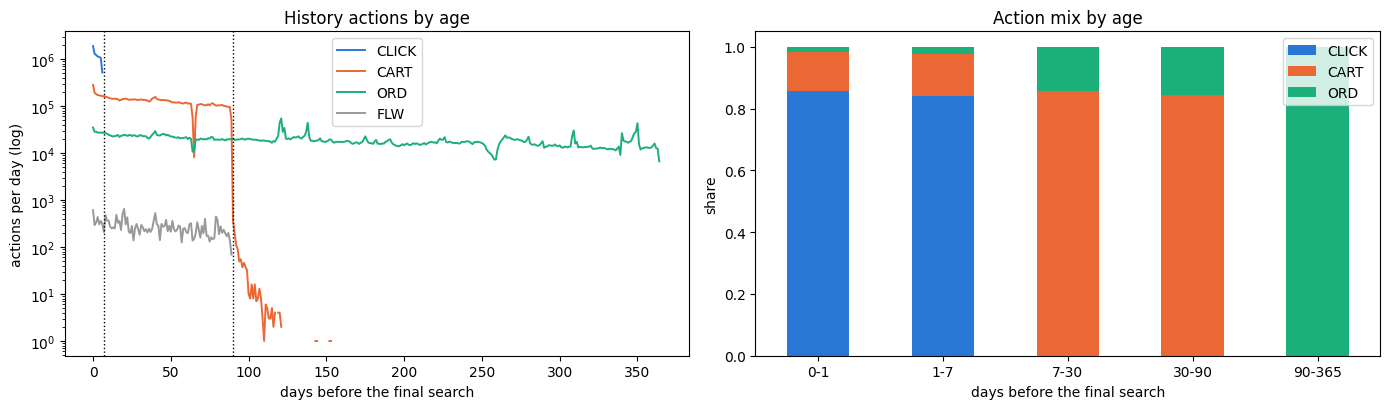

Counts by age bin:


,CLICK,CART,ORD,FLW
0-1,1882605,281476,34889,608
1-7,6315695,1036874,164786,2025
7-30,0,3266105,547330,7345
30-90,0,6819657,1267578,14416
90-365,0,1180,4733073,0


Share by age bin:


,CLICK,CART,ORD
0-1,0.856,0.128,0.016
1-7,0.840,0.138,0.022
7-30,0.000,0.856,0.144
30-90,0.000,0.843,0.157
90-365,0.000,0.000,1.000


In [ ]:
d = np.minimum(H.days.values, 365.999).astype(int)
daily = pd.DataFrame({TYPE_NAME[k]: np.bincount(d[H.t.values == k], minlength=366) for k in range(4)})

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for name, c in zip(["CLICK", "CART", "ORD", "FLW"], ["#2a78d6", "#eb6834", "#1baf7a", "#999999"]):
    ax[0].plot(daily.index, daily[name].replace(0, np.nan), label=name, color=c, lw=1.4)
ax[0].set_yscale("log"); ax[0].set_xlabel("days before the final search"); ax[0].set_ylabel("actions per day (log)")
ax[0].set_title("History actions by age"); ax[0].legend()
for e in WIN_EDGES:
    ax[0].axvline(e, color="k", ls=":", lw=1)

bins = [0, 1, 7, 30, 90, 366]
lab = ["0-1", "1-7", "7-30", "30-90", "90-365"]
by_bin = pd.DataFrame({t: [daily[t].iloc[lo:hi].sum() for lo, hi in zip(bins[:-1], bins[1:])]
                       for t in ["CLICK", "CART", "ORD", "FLW"]}, index=lab)
share = by_bin[["CLICK", "CART", "ORD"]].div(by_bin[["CLICK", "CART", "ORD"]].sum(axis=1), axis=0)
share.plot(kind="bar", stacked=True, ax=ax[1], color=["#2a78d6", "#eb6834", "#1baf7a"], rot=0)
ax[1].set_title("Action mix by age"); ax[1].set_xlabel("days before the final search"); ax[1].set_ylabel("share")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_history_by_age.png", dpi=150); plt.show()

print("Counts by age bin:"); display(by_bin)
print("Share by age bin:"); display(share.round(3))

**Funnel ratios inside each window.** If the inverted funnel is caused by how long JD keeps each action type, the ratios should look normal again once we compare like with like, i.e. only inside the most recent window where every type is kept.

In [ ]:
win = np.digitize(H.days.values, WIN_EDGES).astype(np.int8)       # 0: <7d, 1: 7-90d, 2: >=90d
H["win"] = win
tab = pd.crosstab(pd.Series(win, name="window").map(dict(enumerate(WIN_NAMES))),
                  pd.Series(H.t.values, name="type").map(dict(enumerate(TYPE_NAME))))
tab = tab.reindex(WIN_NAMES).reindex(columns=TYPE_NAME, fill_value=0)
tab["clicks per cart"] = (tab.CLICK / tab.CART.replace(0, np.nan)).round(2)
tab["carts per order"] = (tab.CART / tab.ORD.replace(0, np.nan)).round(2)
display(tab)
full = H.t.value_counts(normalize=True).rename(dict(enumerate(TYPE_NAME))).round(3)
print("Whole-history shares (what the interim report showed):", full.to_dict())

# Pin the retention cutoffs with daily counts around day 7 and day 90 (open question in the guide)
print("\nDaily counts around the cutoffs:")
display(daily.loc[list(range(4, 11)) + list(range(86, 95)), ["CLICK", "CART", "FLW", "ORD"]])

type,CLICK,CART,FLW,ORD,clicks per cart,carts per order
window,,,,,,
0-7d,8198300,1318350,2633,199675,6.22,6.60
7-90d,0,10085762,21761,1814908,0.00,5.56
90-365d,0,1180,0,4733073,0.00,0.00


Whole-history shares (what the interim report showed): {'CART': 0.432, 'CLICK': 0.311, 'ORD': 0.256, 'FLW': 0.001}

Daily counts around the cutoffs:


,CLICK,CART,FLW,ORD
4,1100103,167830,303,27101
5,1058206,165785,358,27222
6,515001,160947,308,26891
7,0,162599,208,27114
8,0,158405,477,26623
9,0,155039,365,25785
10,0,150393,364,24422
86,0,96547,169,19565
87,0,96028,199,19429
88,0,95379,135,19791


**Does a user's history length change what their history looks like?** If retention drives the mix, a user whose history only reaches back a few days will look like a "clicker" and a user whose history reaches back a year will look like a "buyer", whatever they actually prefer.

In [ ]:
span = H.groupby("user").days.max()
ord_share = H.assign(o=(H.t == 3)).groupby("user").o.mean()
click_share = H.assign(c=(H.t == 0)).groupby("user").c.mean()
sb = pd.cut(span, [0, 1, 7, 30, 90, 180, 366], right=False)
print("Mean per-user action share by how far back the user's history reaches (days):")
display(pd.DataFrame({"users": sb.value_counts(sort=False), "click share": click_share.groupby(sb, observed=False).mean(),
                      "order share": ord_share.groupby(sb, observed=False).mean()}).round(3))

Mean per-user action share by how far back the user's history reaches (days):


,users,click share,order share
days,,,
"[0, 1)",2903,0.842,0.025
"[1, 7)",4164,0.819,0.041
"[7, 30)",7769,0.492,0.100
"[30, 90)",22643,0.352,0.101
"[90, 180)",19477,0.301,0.235
"[180, 366)",114727,0.250,0.348


### What this means for the model

*(Numbers in this box are from the outputs above.)*

1. **The inverted funnel is a logging artifact, not user behaviour.** Clicks exist only in the last 7 days (none of the 8.2M clicks is older than 7 days), carts and follows only in the last 90 days, and orders for the whole year. Past day 90 the history is almost entirely orders (4,733,073 orders vs 1,180 carts). Over the whole history, carts are 43%, clicks 31% and orders 26%. Inside the 0–7 day window, where every type is still kept, clicks outnumber carts 6.2 to 1 and carts outnumber orders 6.6 to 1, which is a normal funnel.
2. **A missing click on an old item means "not recorded", not "not clicked".** A user who bought something 200 days ago almost surely clicked it first. So "this user never clicked shop X" is only informative for the last 7 days.
3. **Whole-history shares measure how far back a user's log goes, not their taste.** The table above shows it: users whose history spans less than a week are mostly clicks, users whose history spans a year are mostly orders.

> **Decision D6: build every history feature inside a time window**, using windows that follow the retention cutoffs: **0–7 days** (clicks, carts, follows, orders), **7–90 days** (carts, follows, orders) and **90–365 days** (orders only). Counts and shares are computed per window, never over the whole history, and each user × candidate match also gets the **days since the most recent matching action**. Pointwise "share of clicks" over the full history is not used anywhere.

The roles of the fields follow from this (the professor's last point):

| Field | Role |
|---|---|
| `candidate_wid_list` + product metadata | the items we score. 80.5% are cold, so they are described by shop, brand and category, not by their ID |
| `candidate_label_list` | the target only, never an input |
| `history_*` lists | input context: what this user cares about, and how recently |
| `history_time_list` | turns history into time windows and recency |
| `query` | context shared by every candidate in the slate. Every candidate was retrieved for it, so it can only help a little |

### Check for leakage from the final search itself (D11)

Does history actions logged a second or two before the search come from the search itself? If they did, an engaged candidate would often show up in history just before the search and the model would learn to copy it. We compare how often engaged and ignored candidates appear in the same user's history within a few seconds, minutes and hours.

In [ ]:
KEY = np.int64(10_000_000_000)
def ukey(user, val):
    # one int64 per (user, id) pair, for fast joins
    val = np.asarray(val, dtype=np.int64)
    assert val.max(initial=0) < KEY, "ids too large for the key trick"
    return np.asarray(user, dtype=np.int64) * KEY + val

hk_all = ukey(H.user.values, H.wid.values)
ck_all = ukey(C.user.values, C.wid.values)
rows = []
for sec in [5, 60, 600, 3600, 86400]:
    recent = np.unique(hk_all[H.days.values * 86400 <= sec])
    hit = np.isin(ck_all, recent)
    rows.append(dict(within=f"{sec:,} s", engaged=hit[C.label.values > 0].mean(), ignored=hit[C.label.values == 0].mean()))
leak = pd.DataFrame(rows); leak["ratio"] = leak.engaged / leak.ignored.replace(0, np.nan)
display(leak.round(4))
print("History actions within 60 s of the search:", f"{(H.days.values * 86400 <= 60).mean():.2%}")

,within,engaged,ignored,ratio
0,5 s,0.0011,0.0000,95.8525
1,60 s,0.0165,0.0005,32.3327
2,600 s,0.0364,0.0017,21.5322
3,"3,600 s",0.0440,0.0022,20.0442
4,"86,400 s",0.0574,0.0030,18.9603


History actions within 60 s of the search: 0.25%


In [ ]:
# D11 follow-up: are history actions just before the search logged from the search itself?
# Runs straight after the leakage check above.
# It reads the raw file line by line, so it covers every user whatever MAX_USERS is set to.
# Needs only BEHAVIOR_PATH and ART_DIR. Uses little RAM. Expect a few minutes on standard Colab.
#
# A candidate is matched to the user's MOST RECENT action on that same product, within the last hour.
# Each match falls in exactly one time band, so the bands do not overlap.
import bisect, os, time
from collections import Counter
import pandas as pd

CHECK_FULL_FILE = True      # stop if the file is incomplete (the Drive mount has returned partial files before)
EDGES = [1, 2, 3, 5, 10, 30, 60, 120, 600, 3600]      # upper edge of each band, in seconds
BANDS = ["1 s", "2 s", "3 s", "4-5 s", "6-10 s", "11-30 s", "31-60 s", "1-2 min", "2-10 min", "10-60 min"]
CONTROL = "10-60 min"       # comparison band: too far from the search to be the search itself
LEVEL = {"CLICK": 1, "CART": 2, "ORD": 3}             # label each action type maps to; FLW has no label
SEP = "\x18"                # ^X separates terms inside a query

def wid_key(x):
    return x.split(".")[0]  # ids can be written as "123.0"

cnt = Counter()
n_rows = n_kept = n_bad = n_cands = n_eng = n_actions = 0
t0 = time.time()
with open(BEHAVIOR_PATH, encoding="utf-8") as fh:
    if not fh.readline().startswith("query\t"):   # no header line
        fh.seek(0)
    for line in fh:
        f = line.rstrip("\n").split("\t")
        if len(f) != 7:
            n_bad += 1
            continue
        n_rows += 1
        q, cw, cl, hq, hw, ht, hg = f
        labs = [int(float(x)) for x in cl.split("_")]
        cands = cw.split("_")
        if max(labs) <= 0:                        # D1: same 171,728 slates as the pipeline
            continue
        n_kept += 1
        n_cands += len(cands)
        n_eng += sum(l > 0 for l in labs)
        if not hw:
            continue
        h_wid, h_type, h_qry, gaps = hw.split("_"), ht.split("_"), hq.split("_"), hg.split("_")
        k = min(len(h_wid), len(h_type), len(h_qry), len(gaps) - 1)
        n_actions += k

        # walk back from the search; the first time we meet a product is its most recent action
        seen, bands_hit, elapsed = {}, set(), 0.0
        for i in range(k - 1, -1, -1):
            elapsed += float(gaps[i + 1])
            if elapsed > EDGES[-1]:
                break
            b = bisect.bisect_left(EDGES, elapsed)
            cnt["actions", b] += 1
            bands_hit.add(b)
            seen.setdefault(wid_key(h_wid[i]), (b, h_type[i], h_qry[i]))
        for b in bands_hit:
            cnt["users", b] += 1
        if not seen:
            continue

        test_q_terms = set(q.split(SEP))
        for w, l in zip(cands, labs):
            hit = seen.get(wid_key(w))
            if hit is None:
                continue
            b, a_type, a_qry = hit
            g = "eng" if l > 0 else "ign"
            cnt["n", g, b] += 1
            if a_qry == "-1":
                cnt["queryless", g, b] += 1
            else:
                cnt["has_query", g, b] += 1
                cnt["same_query", g, b] += a_qry == q
                cnt["shares_term", g, b] += bool(test_q_terms & set(a_qry.split(SEP)))
            if l > 0:
                cnt["type", a_type, b] += 1
                cnt["exact", b] += LEVEL.get(a_type) == l
                if a_type in ("CART", "ORD"):
                    cnt["reached", a_type, b] += l >= LEVEL[a_type]
        if n_kept % 50000 == 0:
            print(f"  {n_kept:,} slates  {time.time() - t0:.0f}s", flush=True)

print(f"rows {n_rows:,} | kept {n_kept:,} | incomplete lines {n_bad:,} | candidates {n_cands:,} | "
      f"engaged {n_eng:,} | history actions {n_actions:,} | {time.time() - t0:.0f}s")
if CHECK_FULL_FILE:
    assert (n_rows, n_kept, n_cands, n_eng) == (173_831, 171_728, 15_348_717, 320_896), "file is incomplete: fix this first"

def rate(num, den):
    return num / den if den else float("nan")

rng_b = range(len(BANDS))
n_ign = n_cands - n_eng

# Step 2: where does the engagement rate return to normal?
t_bands = pd.DataFrame([dict(
    time_since_last_action=BANDS[b],
    history_actions=cnt["actions", b],
    users=cnt["users", b],
    engaged=cnt["n", "eng", b],
    ignored=cnt["n", "ign", b],
    engaged_rate=rate(cnt["n", "eng", b], cnt["n", "eng", b] + cnt["n", "ign", b])) for b in rng_b])
t_bands["cum_pct_of_all_actions"] = t_bands.history_actions.cumsum() / n_actions
t_bands["cum_pct_of_engaged_cands"] = t_bands.engaged.cumsum() / n_eng

# Step 3a: does the action fit the label? Engaged candidates only.
# cart_reached_cart: a CART action whose label is 2 or 3. order_reached_order: an ORD action whose label is 3.
# Compare with the control band. A true leak pushes both towards 100%.
t_type = pd.DataFrame([dict(
    time_since_last_action=BANDS[b],
    engaged=cnt["n", "eng", b],
    last_click=cnt["type", "CLICK", b],
    last_cart=cnt["type", "CART", b],
    last_follow=cnt["type", "FLW", b],
    last_order=cnt["type", "ORD", b],
    exact_type_label_match=rate(cnt["exact", b], cnt["n", "eng", b]),
    cart_reached_cart=rate(cnt["reached", "CART", b], cnt["type", "CART", b]),
    order_reached_order=rate(cnt["reached", "ORD", b], cnt["type", "ORD", b])) for b in rng_b])

# Step 3b: which query was the action under?
# queryless = share of actions with -1. same_query and shares_term = share of actions that have a query.
t_query = pd.DataFrame([dict(
    time_since_last_action=BANDS[b],
    eng_queryless=rate(cnt["queryless", "eng", b], cnt["n", "eng", b]),
    ign_queryless=rate(cnt["queryless", "ign", b], cnt["n", "ign", b]),
    eng_same_query=rate(cnt["same_query", "eng", b], cnt["has_query", "eng", b]),
    ign_same_query=rate(cnt["same_query", "ign", b], cnt["has_query", "ign", b]),
    eng_shares_term=rate(cnt["shares_term", "eng", b], cnt["has_query", "eng", b]),
    ign_shares_term=rate(cnt["shares_term", "ign", b], cnt["has_query", "ign", b])) for b in rng_b])

print(f"\nStep 2: engagement rate by time band. Control band: {CONTROL}.")
display(t_bands.round(4))
print("\nStep 3a: action type vs label, engaged candidates")
display(t_type.round(4))
print("\nStep 3b: query behind the action")
display(t_query.round(4))

os.makedirs(f"{ART_DIR}/tables", exist_ok=True)
t_bands.to_csv(f"{ART_DIR}/tables/leak_bands.csv", index=False)
t_type.to_csv(f"{ART_DIR}/tables/leak_type_vs_label.csv", index=False)
t_query.to_csv(f"{ART_DIR}/tables/leak_query.csv", index=False)

  50,000 slates  4s
  100,000 slates  8s
rows 173,831 | kept 171,728 | incomplete lines 0 | candidates 15,348,717 | engaged 320,896 | history actions 26,384,212 | 14s

Step 2: engagement rate by time band. Control band: 10-60 min.


,time_since_last_action,history_actions,users,engaged,ignored,engaged_rate,cum_pct_of_all_actions,cum_pct_of_engaged_cands
0,1 s,8570,7966,2133,626,0.7731,0.0003,0.0066
1,2 s,330,295,34,26,0.5667,0.0003,0.0068
2,3 s,400,378,45,36,0.5556,0.0004,0.0069
3,4-5 s,805,752,149,67,0.6898,0.0004,0.0074
4,6-10 s,2535,2262,452,322,0.5840,0.0005,0.0088
5,11-30 s,22414,16465,1956,2788,0.4123,0.0013,0.0149
6,31-60 s,39130,25275,2025,4215,0.3245,0.0028,0.0212
7,1-2 min,66080,32159,2179,5414,0.2870,0.0053,0.0280
8,2-10 min,251201,41773,3908,12241,0.2420,0.0148,0.0401
9,10-60 min,320919,28332,2355,7500,0.2390,0.0270,0.0475



Step 3a: action type vs label, engaged candidates


,time_since_last_action,engaged,last_click,last_cart,last_follow,last_order,exact_type_label_match,cart_reached_cart,order_reached_order
0,1 s,2133,1715,270,0,148,0.8317,0.9926,0.8243
1,2 s,34,27,7,0,0,0.5882,0.7143,NaN
2,3 s,45,34,11,0,0,0.6444,0.8182,NaN
3,4-5 s,149,109,40,0,0,0.5638,0.9500,NaN
4,6-10 s,452,360,92,0,0,0.7146,0.9239,NaN
5,11-30 s,1956,1637,314,0,5,0.7224,0.8758,0.4000
6,31-60 s,2025,1729,292,0,4,0.6820,0.7945,0.5000
7,1-2 min,2179,1809,358,0,12,0.6567,0.7654,0.5833
8,2-10 min,3908,3305,579,0,24,0.6717,0.7323,0.5000
9,10-60 min,2355,2057,277,0,21,0.6917,0.7076,0.6190



Step 3b: query behind the action


,time_since_last_action,eng_queryless,ign_queryless,eng_same_query,ign_same_query,eng_shares_term,ign_shares_term
0,1 s,0.6287,0.8658,0.0,0.0,0.9343,0.8095
1,2 s,0.7353,0.7692,0.0,0.0,1.0000,1.0000
2,3 s,0.6889,0.7778,0.0,0.0,0.9286,0.8750
3,4-5 s,0.6510,0.8507,0.0,0.0,0.9038,0.7000
4,6-10 s,0.5487,0.7112,0.0,0.0,0.9363,0.9140
5,11-30 s,0.4821,0.6445,0.0,0.0,0.9309,0.8406
6,31-60 s,0.4815,0.5649,0.0,0.0,0.9076,0.8495
7,1-2 min,0.5168,0.5235,0.0,0.0,0.8936,0.8236
8,2-10 min,0.5440,0.5282,0.0,0.0,0.8642,0.8109
9,10-60 min,0.5546,0.5755,0.0,0.0,0.8694,0.7789


> **Decision D11: drop history actions exactly 1 second before the search (`LEAK_GUARD_SECONDS = 1`).** The check above shows a sharp anomaly at 1 second: 8,570 actions against 330 at 2 seconds, and 77% engagement against about 24% for actions 10–60 minutes before the search. We cannot prove these actions come from the search itself, but dropping them removes only 0.03% of history actions. Engagement falls smoothly after 1 second, which fits normal recency, so a larger guard would remove real signal. The guard is applied while parsing (Section 2), so user-level values such as `user_recency_days` exclude the dropped actions too, and the user split uses each user's original history length.

In [ ]:
del hk_all, ck_all
_ = gc.collect()

## 4. Training rows: negative sampling

> **Decision D4: binary target, engaged = label 1, 2 or 3.** 70% of positives are click-only and purchases are only 0.13% of candidates, so a graded model has very little to learn from at the top grades. The binary model predicts "will engage", and the grades are kept for NDCG@10, where a purchase ranked first earns more than a click. Training on grades is the optional LambdaRank comparison in step 3.

> **Decision D8: in training only, keep every positive plus 20 random negatives per slate.** Label 0 means "shown but ignored", but with up to 200 items and no display order, some were probably never seen, so it is a noisy negative. Keeping all 12M train negatives would not fit next to the features; 20 per slate cuts train rows to about a quarter while keeping every positive. Because the slate is already shuffled (D2), the first 20 negatives in a slate are a random sample. Validation and test keep **full slates**, because that is the task we are scored on. Products never shown to a user are never used as negatives.

> **Decision D12: report training performance on full slates too.** The guideline asks for training and testing performance. Scoring the model on its own sampled training rows would not be comparable (21 candidates instead of ~89), so `TRAIN_EVAL_USERS` (10,000) random train users also keep their full slate. Only their sampled rows are used for fitting (`fit` column); their full slates are used only to measure training NDCG@10 and MRR, so a train/test gap shows overfitting.

Impressions per product (how many train slates show it) are counted **before** sampling, from train users only.

In [ ]:
is_tr = C.split.values == 0
neg_tr = is_tr & (C.label.values == 0)
neg_rank = np.full(len(C), 1 << 30, np.int64)
neg_rank[neg_tr] = C[neg_tr].groupby("user").cumcount().values
fit = is_tr & ((C.label.values > 0) | (neg_rank < NEG_PER_SLATE))      # rows the model is trained on

# a random subset of train users also keeps its full slate, so we can report training performance on full slates
tr_users = np.flatnonzero(split_of == 0)
train_eval = np.zeros(n_users, bool)
train_eval[rng.choice(tr_users, min(TRAIN_EVAL_USERS, tr_users.size), replace=False)] = True
U["train_eval"] = train_eval
keep = np.ones(len(C), bool)   # keep full train slates until the within-slate percentiles are computed (end of section 6), then drop


impr_train = pd.Series(C.wid.values[is_tr]).value_counts()     # label-free count of train slates showing each product
K = C[keep].reset_index(drop=True)                             # K = the rows we build features for
K["fit"] = fit[keep]
K["train_eval"] = train_eval[K.user.values]
del neg_rank, neg_tr, fit; gc.collect()
print(K.groupby("split").agg(rows=("label", "size"), fit_rows=("fit", "sum"),
                             pos_rate=("label", lambda s: (s > 0).mean())).rename(index=SPLITS))

           rows  fit_rows  pos_rate
split                              
train  12275473   2937620  0.020890
val     1538177         0  0.021028
test    1535067         0  0.020918


## 5. Product metadata

We read the 122 parquet chunks once, keep metadata only for products that appear in a kept candidate row or in someone's history, and in the same pass compute the **query–name overlap** for each kept candidate row (share of query terms that appear in the product name). Doing the overlap chunk by chunk means we never hold 12M product names in memory.

Missing metadata becomes -1 ("unknown"), and an unknown shop, brand or category never matches anything (0.7% of candidates and 5.7% of history products have no metadata).

In [ ]:
META_COLS = ["wid", "name", "brand_id", "brand_name", "cate_id_1", "cate_name_1", "cate_id_2",
             "cate_name_2", "cate_id_3", "cate_name_3", "cate_id_4", "cate_name_4", "shop_id"]
ATTRS = ["shop_id", "brand_id", "cate_id_1", "cate_id_2", "cate_id_3", "cate_id_4"]
cat1_catalogue = pd.Series(dtype=np.int64)     # products per level-1 category over the whole catalogue (team 3 feature)

need = np.unique(np.concatenate([K.wid.values, H.wid.values]))
k_order = np.argsort(K.wid.values, kind="stable"); k_sorted = K.wid.values[k_order]
k_user = K.user.values
name_overlap = np.full(len(K), np.nan, np.float32)
name_len = np.full(len(K), np.nan, np.float32)
meta_parts = []
files = sorted(glob.glob(f"{CHUNKS_DIR}/*.parquet"))
assert files, f"no parquet chunks in {CHUNKS_DIR}"
t0 = time.time()
for i, fp in enumerate(files):
    ch = pd.read_parquet(fp)
    ch.columns = META_COLS[: len(ch.columns)]
    w = pd.to_numeric(ch["wid"], errors="coerce")
    ch, w = ch[w.notna().values], w[w.notna()].astype(np.int64).values
    m = np.isin(w, need)
    c1_all = pd.to_numeric(ch["cate_id_1"], errors="coerce").dropna().astype(np.int64).value_counts()
    cat1_catalogue = cat1_catalogue.add(c1_all, fill_value=0)
    part = {"wid": w[m]}
    for a in ATTRS:
        v = pd.to_numeric(ch[a].values[m], errors="coerce")
        part[a] = np.where(np.isnan(v) | (v <= 0), -1, v).astype(np.int64)
    meta_parts.append(pd.DataFrame(part))
    # query-name overlap for the kept candidate rows whose product is in this chunk
    lo = np.searchsorted(k_sorted, w, "left"); hi = np.searchsorted(k_sorted, w, "right")
    names = ch["name"].values
    for j in np.flatnonzero(hi > lo):
        nm = names[j]
        terms = set(nm.split(SEP_Q)) if isinstance(nm, str) and nm else set()
        rows = k_order[lo[j]:hi[j]]
        name_len[rows] = len(terms)
        for r in rows:
            qt = q_terms[k_user[r]]
            if qt:
                name_overlap[r] = len(qt & terms) / len(qt)
    if (i + 1) % 20 == 0:
        print(f"  {i + 1}/{len(files)} chunks  {time.time() - t0:.0f}s", flush=True)

META = pd.concat(meta_parts, ignore_index=True).drop_duplicates("wid").sort_values("wid").reset_index(drop=True)
del meta_parts; gc.collect()

def lookup(wids, col):
    idx = np.clip(np.searchsorted(META.wid.values, wids), 0, len(META) - 1)
    hit = META.wid.values[idx] == wids
    return np.where(hit, META[col].values[idx], -1), hit

assert META[ATTRS].max().max() < 2 ** 31
for a in ATTRS:
    K[a], hit = lookup(K.wid.values, a)
    H[a] = lookup(H.wid.values, a)[0].astype(np.int32)
K["cand_has_meta"] = hit.astype(np.int8)
K["name_overlap"], K["name_len"] = name_overlap, name_len
print(f"metadata for {len(META):,} products | candidates with metadata {K.cand_has_meta.mean():.1%} | "
      f"history with shop known {(H.shop_id.values > 0).mean():.1%} | {time.time() - t0:.0f}s")

  20/122 chunks  306s
  40/122 chunks  606s
  60/122 chunks  919s
  80/122 chunks  1222s
  100/122 chunks  1545s
  120/122 chunks  1869s
metadata for 11,509,772 products | candidates with metadata 99.5% | history with shop known 94.8% | 2207s


### History cap

> **Decision D14: no history cap (`HISTORY_CAP = None`).** User × product features use each user's full history, changed from the interim report's last-100 cap. With that cap, a heavy user's last 100 actions can span only a few days, which leaves their 7–90 and 90–365 day windows empty.

In [ ]:
H_full = H
if HISTORY_CAP:
    from_end = H_full.groupby("user").cumcount(ascending=False).to_numpy()
    H = H_full[from_end < HISTORY_CAP].reset_index(drop=True)
    del from_end
print(f"history actions: full {len(H_full):,} | used for user x product features {len(H):,} (cap {HISTORY_CAP})")

history actions: full 26,375,642 | used for user x product features 26,375,642 (cap None)


## 6. Features

> **Decision D7: feature families.** All history features are per window (D6) and come with recency.
>
> | Family | Features | Why |
> |---|---|---|
> | Item repeat | actions on this exact product by type and window (click/cart/order in 0–7d, cart/order in 7–90d, order in 90–365d, follows), days since the last one, type of the last one | Same-product lift is 13.3× (interim report, Table 6) |
> | Shop, brand, category affinity | for each of shop, brand, category level 3 and 4: count and **share of the user's actions in that window** that match, plus days since the last match | 90.5% of engaged products are new to the user, so matches on attributes have to carry most of the signal (shop lift 3.7×, brand 1.6×) |
> | Popularity | actions on the product in each window across **train users' histories only**, number of train slates showing it, shop popularity | engagement rises from 0.99% (cold) to 5.16% (10+ past actions) |
> | Query context | share of query terms in the product name, name length, query length, whether the user issued this query or its terms before | every candidate was retrieved for the query, so this is context, not the main signal |
> | User context | history length per window, days since the user's last action, share of actions with no query | lets the model treat heavy, light and cold users differently |
> | Slate context | slate length, and the candidate's percentile within its own slate for popularity, overlap and shop affinity | a pointwise model scores each row alone; percentiles tell it how a candidate compares with the others it competes with |
>
> Within-slate percentiles are computed on **full slates for every split**, train included: train slates are only cut down to the sampled rows (D8) after the percentiles are computed, so a train candidate is compared with exactly the same competitors as a validation or test candidate.
>
> Not used: list position (D2), raw product/shop/brand IDs (mostly cold, and they would overfit), whole-history action shares (D6), and query-term embeddings (planned for a later model).

In [ ]:
t0 = time.time()
kw = K.wid.values; ku = K.user.values
user_win = np.stack([np.bincount(H.user.values[H.win.values == w], minlength=n_users) for w in range(3)], axis=1)

def count_by_key(keys, target):
    vc = pd.Series(keys).value_counts()
    return vc.reindex(target).fillna(0).to_numpy(np.float32)

# ---- item repeat features ----
hk = ukey(H.user.values, H.wid.values)
kk = ukey(ku, kw)
m = np.isin(hk, kk)
S = pd.DataFrame(dict(key=hk[m], t=H.t.values[m], win=H.win.values[m], days=H.days.values[m]))
for name, t, w in [("click", 0, 0), ("cart", 1, 0), ("ord", 3, 0), ("cart", 1, 1), ("ord", 3, 1), ("ord", 3, 2)]:
    K[f"item_{name}_w{w}"] = count_by_key(S.key.values[(S.t.values == t) & (S.win.values == w)], kk)
K["item_flw"] = count_by_key(S.key.values[S.t.values == 2], kk)
K["item_days_since"] = S.groupby("key").days.min().reindex(kk).to_numpy(np.float32)
last_t = S.sort_values("days").drop_duplicates("key").set_index("key").t
K["item_last_type"] = pd.Categorical(last_t.reindex(kk).map(dict(enumerate(TYPE_NAME))).fillna("none").values,
                                     categories=["none"] + TYPE_NAME)
del S, hk, m

# ---- shop / brand / category affinity, per window ----
def affinity(attr, name):
    hv, cv = H[attr].values, K[attr].values
    ok = hv > 0
    hk = ukey(H.user.values[ok], hv[ok]); kk = ukey(ku, np.maximum(cv, 0))
    m = np.isin(hk, kk)
    hk, w_, d_ = hk[m], H.win.values[ok][m], H.days.values[ok][m]
    unknown = cv <= 0
    for w in range(3):
        n = count_by_key(hk[w_ == w], kk)
        tot = user_win[ku, w]
        K[f"{name}_n_w{w}"] = np.where(unknown, np.nan, n)
        K[f"{name}_share_w{w}"] = np.where(unknown | (tot == 0), np.nan, n / np.maximum(tot, 1)).astype(np.float32)
    days = pd.Series(d_).groupby(hk).min().reindex(kk).to_numpy(np.float32)
    K[f"{name}_days_since"] = np.where(unknown, np.nan, days)

for attr, name in [("shop_id", "shop"), ("brand_id", "brand"), ("cate_id_3", "cate3"), ("cate_id_4", "cate4")]:
    affinity(attr, name)


# ---- last-session features (actions in the session leading into the search) ----
SESSION_GAP = 1800                                         # 30 min without activity ends a session
s_pos = H.groupby("user").cumcount().to_numpy()            # position of each action in its user's history (H is in time order)
s_brk = (H.gap_before.values > SESSION_GAP) & (s_pos > 0)  # this action starts a new session
s_start = pd.Series(np.where(s_brk, s_pos, 0)).groupby(H.user.values).transform("max").to_numpy()
s_recent = U.user_recency_days.values[H.user.values] * 86400 <= SESSION_GAP   # the session must run into the search
SS = H[(s_pos >= s_start) & s_recent]                      # actions in each user's last session
K["sess_len"] = np.bincount(SS.user.values, minlength=n_users)[ku].astype(np.float32)
K["sess_item_n"] = count_by_key(ukey(SS.user.values, SS.wid.values), kk)
for attr, name in [("shop_id", "shop"), ("brand_id", "brand"), ("cate_id_3", "cate3")]:
    ok = SS[attr].values > 0                               # unknown shop / brand / category never matches
    n = count_by_key(ukey(SS.user.values[ok], SS[attr].values[ok]), ukey(ku, np.maximum(K[attr].values, 0)))
    K[f"sess_{name}_n"] = np.where(K[attr].values > 0, n, np.nan)
del SS, s_pos, s_brk, s_start, s_recent

# ---- popularity, from train users only ----
tr_h = split_of[H_full.user.values] == 0                    # popularity uses the full history (D14)
tr_row = K.split.values == 0                                # F7: train rows exclude their own user's actions
for w in range(3):
    in_w = tr_h & (H_full.win.values == w)
    pop = count_by_key(H_full.wid.values[in_w], kw)
    own = count_by_key(ukey(H_full.user.values[in_w], H_full.wid.values[in_w]), kk)
    K[f"pop_w{w}"] = np.where(tr_row, pop - own, pop)
K["pop_impr_train"] = impr_train.reindex(kw).fillna(0).to_numpy(np.float32)
K.loc[K.split == 0, "pop_impr_train"] -= 1     # don't count the train user's own search
shop_ok = tr_h & (H_full.shop_id.values > 0)
shop_all = count_by_key(H_full.shop_id.values[shop_ok], K.shop_id.values)
shop_own = count_by_key(ukey(H_full.user.values[shop_ok], H_full.shop_id.values[shop_ok]), ukey(ku, np.maximum(K.shop_id.values, 0)))
K["shop_pop"] = np.where(K.shop_id.values > 0, np.where(tr_row, shop_all - shop_own, shop_all), np.nan)
assert (K[["pop_w0", "pop_w1", "pop_w2", "shop_pop"]].fillna(0) >= 0).all().all(), "F7: negative popularity"
del tr_row, in_w, pop, own, shop_all, shop_own

# ---- user, query and slate context ----
for c in ["query_len", "slate_len", "user_hist_len", "user_recency_days", "user_queryless_share",
          "query_seen_before", "query_term_seen_share"]:
    K[c] = U[c].values[ku]
for w in range(3):
    K[f"user_n_w{w}"] = user_win[ku, w]
K["cand_cate1"] = pd.Categorical(K.cate_id_1.values)
for c in ["pop_w0", "pop_impr_train", "name_overlap", "shop_share_w0", "cate3_share_w0"]:
    K[f"{c}_slate_pct"] = K.groupby("user")[c].rank(pct=True).astype(np.float32)

DROP = {"user", "wid", "label", "split", "fit", "train_eval"} | set(ATTRS)

# percentiles above were computed on FULL slates for every split; now drop train rows to the sampled ones (D8)
K = K[(K.split.values != 0) | K.fit.values | K.train_eval.values].reset_index(drop=True)
kw = K.wid.values; ku = K.user.values

FEATURES = [c for c in K.columns if c not in DROP]
print(f"{len(FEATURES)} features for {len(K):,} rows in {time.time() - t0:.0f}s")
print(FEATURES)

66 features for 6,690,773 rows in 94s
['cand_has_meta', 'name_overlap', 'name_len', 'item_click_w0', 'item_cart_w0', 'item_ord_w0', 'item_cart_w1', 'item_ord_w1', 'item_ord_w2', 'item_flw', 'item_days_since', 'item_last_type', 'shop_n_w0', 'shop_share_w0', 'shop_n_w1', 'shop_share_w1', 'shop_n_w2', 'shop_share_w2', 'shop_days_since', 'brand_n_w0', 'brand_share_w0', 'brand_n_w1', 'brand_share_w1', 'brand_n_w2', 'brand_share_w2', 'brand_days_since', 'cate3_n_w0', 'cate3_share_w0', 'cate3_n_w1', 'cate3_share_w1', 'cate3_n_w2', 'cate3_share_w2', 'cate3_days_since', 'cate4_n_w0', 'cate4_share_w0', 'cate4_n_w1', 'cate4_share_w1', 'cate4_n_w2', 'cate4_share_w2', 'cate4_days_since', 'sess_len', 'sess_item_n', 'sess_shop_n', 'sess_brand_n', 'sess_cate3_n', 'pop_w0', 'pop_w1', 'pop_w2', 'pop_impr_train', 'shop_pop', 'query_len', 'slate_len', 'user_hist_len', 'user_recency_days', 'user_queryless_share', 'query_seen_before', 'query_term_seen_share', 'user_n_w0', 'user_n_w1', 'user_n_w2', 'cand_cat

### Do the time-aware features carry signal?

A check on the **validation** slates (not used for training): engagement rate of candidates grouped by how recently the user last touched the same shop, and the same product. A lift above 1 means the candidate is more likely to be engaged than an average candidate.

In [ ]:
V = K[K.split.values == 1]
base = (V.label > 0).mean()
def recency_lift(col):
    b = pd.cut(V[col], [-0.001, 1, 7, 90, 366], labels=["<1d", "1-7d", "7-90d", "90-365d"]).cat.add_categories("never").fillna("never")
    g = (V.label > 0).groupby(b, observed=False).agg(["size", "mean"])
    g.columns = ["candidates", "engagement rate"]; g["lift"] = g["engagement rate"] / base
    return g
print(f"validation engagement rate: {base:.2%}")
lift_tables = {}
for col in ["shop_days_since", "item_days_since", "brand_days_since"]:
    lift_tables[col] = recency_lift(col)
    print(f"\nLast matching action: {col}"); display(lift_tables[col].round(4))

validation engagement rate: 2.10%

Last matching action: shop_days_since


,candidates,engagement rate,lift
shop_days_since,,,
<1d,51732,0.0696,3.3093
1-7d,20199,0.0593,2.8205
7-90d,25218,0.0591,2.8117
90-365d,7298,0.0552,2.6260
never,1433730,0.0179,0.8509



Last matching action: item_days_since


,candidates,engagement rate,lift
item_days_since,,,
<1d,6302,0.2788,13.2584
1-7d,2656,0.1931,9.1852
7-90d,2315,0.2212,10.5176
90-365d,519,0.2197,10.4457
never,1526385,0.0193,0.9175



Last matching action: brand_days_since


,candidates,engagement rate,lift
brand_days_since,,,
<1d,165256,0.0332,1.5804
1-7d,66613,0.0271,1.2879
7-90d,79249,0.0264,1.2548
90-365d,21036,0.0291,1.3835
never,1206023,0.0185,0.8811


## 7. Collaborative-filtering baseline: implicit matrix factorisation

We should frame our model against conventional recommender baselines such as NCF and NMF and diagnose where they fall short. We build the simplest member of that family here, because it needs the full history table, which the later steps do not load.

> **Decision D13: MF baseline = truncated SVD of the user × product history matrix.** Each cell is log(1 + number of actions the user took on that product), over the whole history and ignoring time, which is how a conventional CF baseline treats implicit feedback. We keep products with at least `MF_MIN_COUNT` history actions, plus every candidate with at least one, and factorise with 32 latent factors. A candidate's score is the dot product of the user and product factors. A candidate that no user ever touched (**cold**) has no factor and gets score 0.
>
> We expect it to do poorly for two structural reasons, which is the point of including it: 80.5% of distinct candidates (56.7% of candidate rows) are cold, so it cannot tell most candidates apart. And it mixes 7-day clicks with year-old orders as if they were the same signal (Section 3). NCF and NMF share both limits because they also learn only from product IDs. Steps 2 and 3 measure this gap.
>
> The MF score is saved as `score_mf` and is **not** a LightGBM feature, so the two can be compared cleanly. Adding it as a LightGBM feature is a possible improvement.

In [ ]:
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
t0 = time.time()
hist_cnt = pd.Series(H_full.wid.values).value_counts()
items = hist_cnt.index.values[(hist_cnt.values >= MF_MIN_COUNT) | np.isin(hist_cnt.index.values, K.wid.values)]
item_index = pd.Index(items)
col = item_index.get_indexer(H_full.wid.values); ok = col >= 0
X = csr_matrix((np.ones(ok.sum(), np.float32), (H_full.user.values[ok], col[ok])), shape=(n_users, len(items)))
X.sum_duplicates(); X.data = np.log1p(X.data)
k = min(MF_DIM, min(X.shape) - 1)
Uf, s, Vt = svds(X, k=k, random_state=SEED)
uvec, ivec = (Uf * s).astype(np.float32), np.ascontiguousarray(Vt.T, dtype=np.float32)
ci = item_index.get_indexer(K.wid.values)
mf = np.zeros(len(K), np.float32)
for st in range(0, len(K), 1_000_000):
    sl = slice(st, st + 1_000_000); c = ci[sl]; w = c >= 0
    part = np.zeros(c.size, np.float32)
    part[w] = np.einsum("ij,ij->i", uvec[K.user.values[sl][w]], ivec[c[w]])
    mf[sl] = part
K["score_mf"] = mf
K["mf_warm"] = (ci >= 0).astype(np.int8)
del X, Uf, Vt, uvec, ivec, ci, col, ok; gc.collect()
print(f"MF: {len(items):,} products x {n_users:,} users, k={k}, {time.time() - t0:.0f}s")
print(f"candidate rows MF can score (warm): {K.mf_warm.mean():.1%} | engaged rows: {K.mf_warm[K.label > 0].mean():.1%}")

MF: 2,757,229 products x 171,728 users, k=32, 34s
candidate rows MF can score (warm): 44.1% | engaged rows: 73.0%


## 8. Inputs for team 3's hybrid NCF (our prior baseline)

Our prior baseline is team 3's model from last term ([github.com/myathetchai/bt4222-team3-jdsearch](https://github.com/myathetchai/bt4222-team3-jdsearch), notebook `3.1_Hybrid_NCF_with_LSTM.ipynb`, the version with reported ranking metrics). It has three parts:
- **user history encoder:** an LSTM with attention over the user's last 200 actions, each one the sum of a product-ID, action-type and time-gap-bin embedding
- **candidate encoder:** the sum of product-ID, brand, shop and four category embeddings
- **15 user "meta" features:** category breadth, history length, click/cart/order ratios, a user cluster, gap statistics and time-decay scores

The three are concatenated and passed through an MLP that predicts 4 classes (none, click, cart, purchase) with class-weighted cross-entropy. They trained and evaluated on lists with every positive plus 4 random negatives per positive.

This section rebuilds those inputs from our parsed data, following their code line by line. Step 2 trains the model.

> **Decision D15: port team 3's model faithfully, but on our data and split.** Kept the same: the meta-feature definitions, the time-gap binning (10 log-spaced bins of the raw gap before each action), the 200-action sequence, the type ordinals (click 1, follow 1.5, cart 2, order 3), the 1:4 sampled lists and the loss. Changed, each in team 3's favour:
> 1. **Full history.** Their preprocessing dropped every history product that was not also one of their sampled candidates, which cut the mean history from 153 to 66 actions and left 4,515 users with no history at all (their `2. Data Preprocessing` output). We keep the full history.
> 2. **Correct candidate attributes.** Their dataset indexes candidates with the *history* product vocabulary but looks up brand, shop and category with the *metadata* vocabulary, so the attribute embeddings belong to other products, and every candidate not seen in history (most of them) collapses to the padding row. We look the attributes up directly.
> 3. **ID vocabulary capped at the 1,000,000 most frequent history products** so the embedding tables fit a Colab T4 GPU. Their vocabulary was smaller because of point 1.
> 4. **User clusters** use their recipe (median imputation, standardise, PCA to 3 components, KMeans with 4 clusters) but are fitted on train users only.
> 5. **Our stratified 80/10/10 split** instead of their 70/15/15, so every model is scored on exactly the same test users.
>
> We evaluate it on their sampled lists *and* on full slates. That separates how much of their reported score came from the evaluation protocol from how good the model is.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
t0 = time.time()
T = H_full                                   # chronological within each user
uid = T.user.values
k_u = np.bincount(uid, minlength=n_users)
t3 = pd.DataFrame(index=pd.RangeIndex(n_users, name="user"))

# category breadth and popularity (team 3: "buying behaviour")
for l in range(1, 5):
    c = T[f"cate_id_{l}"].values; ok = c > 0
    t3[f"nunique_cats_{l}"] = pd.Series(c[ok]).groupby(uid[ok]).nunique().reindex(t3.index).fillna(0).to_numpy()
c1 = T.cate_id_1.values; ok = c1 > 0
log_size = np.log10(cat1_catalogue.astype(float))
t3["avg_log_cat_1_popularity"] = pd.Series(log_size.reindex(c1[ok]).to_numpy()).groupby(uid[ok]).mean().reindex(t3.index).to_numpy()
t3["history_len"] = k_u

# whole-history action ratios (This is what Prof warned about but kept because it is their feature)
for name, code_ in [("click_ratio", 0), ("cart_ratio", 1), ("order_ratio", 3)]:
    t3[name] = np.where(k_u > 0, np.bincount(uid[T.t.values == code_], minlength=n_users) / np.maximum(k_u, 1), np.nan)

# gap statistics on each user's list of gaps before each action, without its last element (their gaps[:-1])
g = T.gap_before.values.astype(np.float64)
keep = np.r_[uid[1:] != uid[:-1], True] == False           # every action except each user's last
cnt = np.bincount(uid[keep], minlength=n_users)
s1 = np.bincount(uid[keep], weights=g[keep], minlength=n_users)
s2 = np.bincount(uid[keep], weights=g[keep] ** 2, minlength=n_users)
mean = s1 / np.maximum(cnt, 1)
ok3 = cnt >= 2
t3["avg_interaction_time_gap"] = np.where(cnt >= 1, mean, np.nan)
t3["std_time_gap"] = np.where(ok3, np.sqrt(np.maximum(s2 / np.maximum(cnt, 1) - mean ** 2, 0)), np.nan)
gk = pd.Series(g[keep]).groupby(uid[keep])
t3["min_gap"] = np.where(ok3, gk.min().reindex(t3.index).to_numpy(), np.nan)
t3["max_gap"] = np.where(ok3, gk.max().reindex(t3.index).to_numpy(), np.nan)
t3["total_active_days"] = np.where(ok3, np.bincount(uid[keep], weights=(g[keep] > 0), minlength=n_users), np.nan)

# time decay: exp(-0.02 * age in days) * type ordinal, summed and averaged (their LAMBDA = 0.02)
cs = pd.Series(g).groupby(uid).cumsum().to_numpy()
age_days = (np.bincount(uid, weights=g, minlength=n_users)[uid] - cs + g) / 86400
ordinal = np.array([1.0, 2.0, 1.5, 3.0])[np.clip(T.t.values, 0, 3)]          # CLICK, CART, FLW, ORD
ordinal[T.t.values < 0] = 3.0                                                 # their mapping sends anything else to 3
decay = np.exp(-0.02 * age_days) * ordinal
t3["total_time_decay"] = np.bincount(uid[keep], weights=decay[keep], minlength=n_users)
t3["avg_time_decay"] = np.where(cnt > 0, t3.total_time_decay / np.maximum(cnt, 1), 0.0)

# user clusters: their recipe, fitted on train users only
CLUSTER_COLS = ["nunique_cats_1", "nunique_cats_2", "nunique_cats_3", "nunique_cats_4", "avg_log_cat_1_popularity",
                "history_len", "avg_interaction_time_gap", "std_time_gap", "min_gap", "max_gap", "total_active_days",
                "click_ratio", "cart_ratio", "order_ratio", "total_time_decay", "avg_time_decay"]
trm = split_of == 0
imp_ = SimpleImputer(strategy="median").fit(t3.loc[trm, CLUSTER_COLS])
sc_ = StandardScaler().fit(imp_.transform(t3.loc[trm, CLUSTER_COLS]))
Z = sc_.transform(imp_.transform(t3[CLUSTER_COLS]))
pca_ = PCA(n_components=3, random_state=SEED).fit(Z[trm])
km_ = KMeans(n_clusters=4, random_state=SEED, init="k-means++", n_init=10).fit(pca_.transform(Z[trm]))
t3["cluster"] = km_.predict(pca_.transform(Z))
T3_META = ["nunique_cats_1", "nunique_cats_2", "nunique_cats_3", "nunique_cats_4", "history_len", "avg_log_cat_1_popularity",
           "click_ratio", "cart_ratio", "order_ratio", "cluster", "avg_interaction_time_gap", "std_time_gap", "max_gap",
           "total_time_decay", "avg_time_decay"]                               # the 15 columns their model reads
print(f"team 3 meta features for {n_users:,} users in {time.time() - t0:.0f}s")
display(t3[T3_META].describe().T[["mean", "50%", "min", "max"]].round(3))

team 3 meta features for 171,728 users in 11s


,mean,50%,min,max
nunique_cats_1,11.733,11.000,0.000,4.000000e+01
nunique_cats_2,22.114,16.000,0.000,1.960000e+02
nunique_cats_3,35.205,22.000,0.000,6.030000e+02
nunique_cats_4,38.896,23.000,0.000,6.600000e+02
history_len,153.590,78.000,0.000,4.802000e+03
avg_log_cat_1_popularity,5.620,5.634,3.073,6.047000e+00
click_ratio,0.304,0.239,0.000,1.000000e+00
cart_ratio,0.417,0.400,0.000,1.000000e+00
order_ratio,0.279,0.228,0.000,1.000000e+00
cluster,1.307,1.000,0.000,3.000000e+00


In [ ]:
# history sequences: the last T3_MAX_LEN actions, as item / type / time-gap-bin indices (0 = padding)
t0 = time.time()
vc = pd.Series(T.wid.values).value_counts()
item_vocab = pd.Index(vc.index[:T3_ITEM_VOCAB])
item_idx = (item_vocab.get_indexer(T.wid.values) + 1).astype(np.int32)
type_idx = np.array([1, 3, 2, 4], np.int8)[np.clip(T.t.values, 0, 3)]        # ordinals 1 < 1.5 < 2 < 3 -> 1..4
type_idx[T.t.values < 0] = 4
t3_bins = np.round(np.expm1(np.linspace(np.log1p(g.min()), np.log1p(g.max()), 10))).astype(np.int64)
time_idx = np.digitize(g, t3_bins).astype(np.int8)                           # 1..10, as in their code

from_end = T.groupby("user").cumcount(ascending=False).to_numpy()
sel = from_end < T3_MAX_LEN
seq_len = np.bincount(uid[sel], minlength=n_users).astype(np.int16)
pos = seq_len[uid[sel]] - 1 - from_end[sel]                                  # 0 = oldest kept action
seq = {name: np.zeros((n_users, T3_MAX_LEN), dt) for name, dt in [("item", np.int32), ("type", np.int8), ("time", np.int8)]}
seq["item"][uid[sel], pos] = item_idx[sel]
seq["type"][uid[sel], pos] = type_idx[sel]
seq["time"][uid[sel], pos] = time_idx[sel]
del from_end, sel, pos, item_idx, type_idx, time_idx

# candidate inputs: product ID from the same history vocabulary, attributes from metadata (fix 2 in D15)
K["t3_wid"] = (item_vocab.get_indexer(K.wid.values) + 1).astype(np.int32)
t3_sizes = {"item": len(item_vocab) + 1, "type": 5, "time": len(t3_bins) + 1}
for a in ["brand_id", "shop_id", "cate_id_1", "cate_id_2", "cate_id_3", "cate_id_4"]:
    v = K[a].values
    seen = pd.Index(np.unique(v[K.fit.values & (v > 0)]))                    # vocabulary from training rows only
    K[f"t3_{a}"] = (seen.get_indexer(v) + 1).astype(np.int32)                 # 0 = unknown
    t3_sizes[a] = len(seen) + 1

# team 3's evaluation lists: every positive plus 4 random negatives per positive (D15)
neg = K.label.values == 0
neg_rank = np.full(len(K), 1 << 30, np.int64)
neg_rank[neg] = K[neg].groupby("user").cumcount().to_numpy()                 # the slate is shuffled, so this is random
K["t3_list"] = ~neg | (neg_rank < T3_NEG_RATIO * U.n_pos.values[K.user.values])
del neg, neg_rank
lst = K[K.t3_list].groupby("user").size()
full = U.slate_len
print(f"done in {time.time() - t0:.0f}s | item vocabulary {len(item_vocab):,} | time bins {t3_bins.tolist()}")
print(f"candidates per search: team 3 lists median {lst.median():.0f} (mean {lst.mean():.1f}) vs full slates median {full.median():.0f} (mean {full.mean():.1f})")
print(f"searches with <= 10 candidates: team 3 lists {(lst <= 10).mean():.1%} vs full slates {(full <= 10).mean():.1%}")

done in 9s | item vocabulary 1,000,000 | time bins [0, 6, 50, 365, 2614, 18701, 133743, 956428, 6839617, 48911484]
candidates per search: team 3 lists median 5 (mean 8.9) vs full slates median 90 (mean 89.4)
searches with <= 10 candidates: team 3 lists 81.2% vs full slates 2.3%


## 9. Save the artifacts

| File | What it is |
|---|---|
| `features.parquet` | one row per kept user × candidate: ids, label, split, `fit`, `train_eval` and `t3_list` flags, every feature, `score_mf` and team 3's candidate indices |
| `users.parquet` | one row per user: split and user-level facts, for the segment analysis |
| `team3_meta.parquet` | team 3's user meta features |
| `team3_seq.npz` | team 3's history sequences (item, type, time-bin indices) |
| `history_full.parquet` | every history action after the 1-second leak guard (D11), uncapped: user, product, action type, days before the search, shop/brand/category. Input to `step3_attention.ipynb`. The save line was added on 8 Nov after the saved run, so this file is missing from the printed file list below; the Drive copy was saved by the same code on 5 Nov |
| `config.json` | the feature list and every setting used, so later steps and reruns are reproducible |
| `tables/*.csv` | small analysis tables (history by age, funnel per window, leakage check, recency lift) for the report |
| `figures/*.png` | the plots |

The last two cells upload to the shared BT4222_artifacts folder only if UPLOAD_ARTIFACTS = True.

In [ ]:
os.makedirs(f"{ART_DIR}/tables", exist_ok=True)
K.to_parquet(f"{ART_DIR}/features.parquet", index=False)
U.assign(user=np.arange(n_users)).to_parquet(f"{ART_DIR}/users.parquet", index=False)
t3.reset_index().to_parquet(f"{ART_DIR}/team3_meta.parquet", index=False)
H_full.to_parquet(f"{ART_DIR}/history_full.parquet", index=False, compression="zstd")
np.savez_compressed(f"{ART_DIR}/team3_seq.npz", item=seq["item"], type=seq["type"], time=seq["time"], length=seq_len, bins=t3_bins)
config = dict(FEATURES=FEATURES, SEED=SEED, NEG_PER_SLATE=NEG_PER_SLATE, TRAIN_EVAL_USERS=TRAIN_EVAL_USERS,
              WIN_EDGES=WIN_EDGES, LEAK_GUARD_SECONDS=LEAK_GUARD_SECONDS, MF_DIM=MF_DIM, MF_MIN_COUNT=MF_MIN_COUNT,
              HISTORY_CAP=HISTORY_CAP, T3_NEG_RATIO=T3_NEG_RATIO, T3_MAX_LEN=T3_MAX_LEN, T3_ITEM_VOCAB=T3_ITEM_VOCAB,
              T3_META=T3_META, T3_SIZES={k: int(v) for k, v in t3_sizes.items()},
              MAX_USERS=MAX_USERS, n_users=int(n_users), n_dropped=int(n_dropped), rows=int(len(K)))
json.dump(config, open(f"{ART_DIR}/config.json", "w"), indent=1)
by_bin.to_csv(f"{ART_DIR}/tables/history_by_age_counts.csv"); share.to_csv(f"{ART_DIR}/tables/history_by_age_share.csv")
tab.to_csv(f"{ART_DIR}/tables/funnel_by_window.csv"); leak.to_csv(f"{ART_DIR}/tables/leak_check.csv", index=False)
daily.to_csv(f"{ART_DIR}/tables/history_daily_counts.csv", index_label="days_before_search")
for c, t in lift_tables.items():
    t.to_csv(f"{ART_DIR}/tables/recency_lift_{c}.csv")
for root, _, fs in os.walk(ART_DIR):
    for f in fs:
        p = os.path.join(root, f); print(f"{os.path.getsize(p) / 1e6:9.1f} MB  {os.path.relpath(p, ART_DIR)}")

     39.6 MB  team3_seq.npz
      3.5 MB  users.parquet
      0.0 MB  config.json
    301.7 MB  features.parquet
     13.1 MB  team3_meta.parquet
      0.1 MB  figures/fig_history_by_age.png
      0.0 MB  tables/history_daily_counts.csv
      0.0 MB  tables/recency_lift_shop_days_since.csv
      0.0 MB  tables/recency_lift_brand_days_since.csv
      0.0 MB  tables/leak_type_vs_label.csv
      0.0 MB  tables/leak_query.csv
      0.0 MB  tables/leak_bands.csv
      0.0 MB  tables/leak_check.csv
      0.0 MB  tables/funnel_by_window.csv
      0.0 MB  tables/history_by_age_share.csv
      0.0 MB  tables/recency_lift_item_days_since.csv
      0.0 MB  tables/history_by_age_counts.csv


In [ ]:
def _drive():
    from google.colab import auth
    auth.authenticate_user()
    from googleapiclient.discovery import build
    return build("drive", "v3")

def _folder_id(svc, create=False):
    return ARTIFACT_FOLDER_ID   # shared BT4222_artifacts, found by id (not by name in your own My Drive)

def drive_upload(names):
    # copy ART_DIR/<name> into My Drive/DRIVE_ARTIFACT_FOLDER (created if missing); re-running overwrites
    from googleapiclient.http import MediaFileUpload
    svc = _drive(); fid = _folder_id(svc, create=True)
    for f in names:
        t0 = time.time()
        old = svc.files().list(q=f"'{fid}' in parents and name='{f}' and trashed=false", fields="files(id)").execute()["files"]
        media = MediaFileUpload(f"{ART_DIR}/{f}", resumable=True, chunksize=100 * 1024 * 1024)
        if old:
            svc.files().update(fileId=old[0]["id"], media_body=media).execute()
        else:
            svc.files().create(body={"name": f, "parents": [fid]}, media_body=media).execute()
        print(f"uploaded {f} to My Drive/{DRIVE_ARTIFACT_FOLDER}  {time.time() - t0:.0f}s")

def drive_download(names):
    # fetch the named files from My Drive/DRIVE_ARTIFACT_FOLDER into ART_DIR, skipping ones already there
    import io
    from googleapiclient.http import MediaIoBaseDownload
    names = [f for f in names if not os.path.exists(f"{ART_DIR}/{f}")]
    if not names:
        return
    svc = _drive(); fid = _folder_id(svc, create=False); os.makedirs(ART_DIR, exist_ok=True)
    for f in names:
        found = svc.files().list(q=f"'{fid}' in parents and name='{f}' and trashed=false", fields="files(id)").execute()["files"]
        if not found:
            raise FileNotFoundError(f"{f} is not in My Drive/{DRIVE_ARTIFACT_FOLDER}. Run the step that makes it first.")
        with io.FileIO(f"{ART_DIR}/{f}", "wb") as fh:
            dl = MediaIoBaseDownload(fh, svc.files().get_media(fileId=found[0]["id"]), chunksize=100 * 1024 * 1024)
            done = False
            while not done:
                _, done = dl.next_chunk()
        print("downloaded", f)

STEP1_FILES = ["features.parquet", "users.parquet", "config.json", "team3_meta.parquet", "team3_seq.npz", "history_full.parquet"]
STEP2_FILES = ["baseline_scores.parquet"]

# Steps 2 and 3 run on different Colab machines, so copy what they need into your own My Drive.
if IN_COLAB and UPLOAD_ARTIFACTS:
    drive_upload(STEP1_FILES)

uploaded features.parquet to My Drive/BT4222_artifacts  12s
uploaded users.parquet to My Drive/BT4222_artifacts  3s
uploaded config.json to My Drive/BT4222_artifacts  3s
uploaded team3_meta.parquet to My Drive/BT4222_artifacts  3s
uploaded team3_seq.npz to My Drive/BT4222_artifacts  3s


In [ ]:
if IN_COLAB and UPLOAD_ARTIFACTS:
    !cd /content/artifacts && zip -qr tables_figures.zip tables figures
    drive_upload(["tables_figures.zip"])

uploaded tables_figures.zip to My Drive/BT4222_artifacts  3s


## Findings (for the report)
- **Inverted funnel = logging windows, not behaviour.** Clicks exist only in the last 7 days, carts and follows only in the last 90, orders for the whole year. Inside 0–7 days the funnel is normal: 6.2 clicks per cart, 6.6 carts per order (Section 3).
- **Possible leakage at 1 second.** 8,570 history actions sit exactly 1 s before the search (330 at 2 s), with 77% engagement vs ~24% at 10–60 min. Dropped (D11); 0.03% of history.
- **Recency signal (validation).** A candidate the user touched less than 1 day ago: engagement lift 13.3× (same product), 3.3× (same shop), 1.6× (same brand) (Section 6).
- **Split and rows.** 171,728 users: 137,380 train / 17,172 val / 17,176 test. Train: 2,937,620 sampled rows (all positives + 20 negatives per slate); val and test keep full slates (~89 candidates).
- **MF coverage.** MF can score 44.1% of candidate rows (73.0% of engaged rows); the rest are cold.
- **Team 3's protocol.** Their lists have a median of 5 candidates vs 90 on full slates; 81.2% of their lists have ≤10 candidates, so Hit@10 is near 1 by design.
- 66 features saved; step 3 uses 65 (`slate_len` removed).